# Walk Exploration

Interactive notebook for exploring random walks and embedding behavior on synthetic and real hypergraphs.

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from hypergraphx import Hypergraph
from hypergraphx.generation.hy_mmsbm_sampling import HyMMSBMSampler

from src.utils import hmrw_embeddings

In [ ]:
def generate_hypergraph_with_labels(seed, n_communities, n_nodes, w, avg_deg_target, max_hye_size):
    rng = np.random.default_rng(seed)
    z = rng.integers(0, n_communities, size=n_nodes)
    u = np.eye(n_communities, dtype=float)[z]

    sampler = HyMMSBMSampler(
        u=u,
        w=w,
        seed=seed,
        max_hye_size=max_hye_size,
        exact_dyadic_sampling=True,
        burn_in_steps=200,
        intermediate_steps=200,
    )
    H = next(sampler.sample(avg_deg=avg_deg_target, allow_rescaling=True))
    nodes_sorted = sorted(H.get_nodes())
    y = z[np.asarray(nodes_sorted, dtype=int)]
    return H, y

In [28]:
def sample_hmrw_walks(H, walk_length=1000, walks_per_node=1, p=1.0, q=1.0, r=1.0, gamma=-1.0, seed=0, return_edge_walks=False):
    nodes = sorted(H.get_nodes())
    idx = {u: i for i, u in enumerate(nodes)}
    edges = [frozenset(e) for e in H.get_edges()]

    n = len(nodes)
    d = np.zeros(n)
    inc_edges = [[] for _ in range(n)]
    for e_i, e in enumerate(edges):
        for u in e:
            i = idx[u]
            d[i] += 1
            inc_edges[i].append(e_i)

    rng = np.random.default_rng(seed)
    walks = []
    edge_walks = []

    # Per-step Stage-1 selected-case counts: [same hyperedge, middle case, other case]
    case_counts = np.zeros((walk_length - 1, 3), dtype=float)
    step_counts = np.zeros(walk_length - 1, dtype=float)

    # Per-step Stage-1 possible-case counts among all candidate hyperedges.
    possible_counts = np.zeros((walk_length - 1, 3), dtype=float)
    possible_totals = np.zeros(walk_length - 1, dtype=float)

    for _ in range(walks_per_node):
        for start in rng.permutation(n):
            v_i = int(start)
            walk = [v_i]
            edge_walk = []
            prev_u_i, prev_e_i = None, None

            for t in range(walk_length - 1):
                cand_e = inc_edges[v_i]
                if not cand_e:
                    walk.append(v_i)
                    edge_walk.append(-1)
                    continue

                raw_e = np.zeros(len(cand_e))
                poss_local = np.zeros(3, dtype=float)
                for k, e2_i in enumerate(cand_e):
                    e2 = edges[e2_i]
                    if len(e2) == 0:
                        continue

                    if prev_e_i is None or prev_u_i is None:
                        a_edge = 1.0
                    else:
                        overlap_excl_v = len((edges[prev_e_i] - {nodes[v_i]}) & (e2 - {nodes[v_i]})) > 0
                        if e2_i == prev_e_i:
                            a_edge = 1.0 / p
                            poss_local[0] += 1.0
                        elif overlap_excl_v:
                            a_edge = 1.0
                            poss_local[1] += 1.0
                        else:
                            a_edge = 1.0 / q
                            poss_local[2] += 1.0

                    size_term = max(len(e2) - 1, 1)
                    raw_e[k] = a_edge * (size_term ** gamma)

                if prev_e_i is not None and prev_u_i is not None:
                    possible_counts[t] += poss_local
                    possible_totals[t] += poss_local.sum()

                s_e = raw_e.sum()
                if s_e <= 0 or not np.isfinite(s_e):
                    next_e_i = int(rng.choice(cand_e))
                else:
                    next_e_i = cand_e[int(rng.choice(len(cand_e), p=raw_e / s_e))]

                # Stage-1 transition case for diagnostics
                if prev_e_i is not None and prev_u_i is not None:
                    if next_e_i == prev_e_i:
                        case_counts[t, 0] += 1.0
                    elif len(edges[prev_e_i] & edges[next_e_i]) > 1:
                        case_counts[t, 1] += 1.0
                    else:
                        case_counts[t, 2] += 1.0
                    step_counts[t] += 1.0

                e2 = edges[next_e_i]
                cand_x = [idx[x] for x in e2 if idx[x] != v_i]
                raw_x = np.zeros(len(cand_x))
                prev_e_nodes = edges[prev_e_i] if prev_e_i is not None else None

                for k, x_i in enumerate(cand_x):
                    if d[x_i] <= 0:
                        continue
                    if prev_u_i is None:
                        a_node = 1.0
                    elif prev_e_nodes is not None and nodes[x_i] in prev_e_nodes:
                        a_node = 1.0
                    else:
                        a_node = 1.0 / r
                    raw_x[k] = a_node * (1.0 / d[x_i])

                s_x = raw_x.sum()
                x_i = cand_x[int(rng.choice(len(cand_x), p=raw_x / s_x))]
                prev_u_i, prev_e_i, v_i = v_i, next_e_i, x_i
                walk.append(v_i)
                edge_walk.append(next_e_i)

            walks.append(walk)
            edge_walks.append(edge_walk)

    case_freq = np.zeros_like(case_counts)
    valid = step_counts > 0
    case_freq[valid] = case_counts[valid] / step_counts[valid, None]

    possible_freq = np.zeros_like(possible_counts)
    valid_possible = possible_totals > 0
    possible_freq[valid_possible] = possible_counts[valid_possible] / possible_totals[valid_possible, None]

    if return_edge_walks:
        return walks, case_freq, possible_freq, edge_walks
    return walks, case_freq, possible_freq

In [29]:
def node_coverage_over_time(walks):
    max_len = max((len(w) for w in walks), default=0)
    sums = np.zeros(max_len, dtype=float)
    counts = np.zeros(max_len, dtype=int)

    for w in walks:
        seen = set()
        for t, v in enumerate(w):
            seen.add(v)
            sums[t] += len(seen)
            counts[t] += 1

    coverage = np.zeros(max_len, dtype=float)
    mask = counts > 0
    coverage[mask] = sums[mask] / counts[mask]

    # Coverage should be non-decreasing in t.
    coverage = np.maximum.accumulate(coverage)
    return coverage


def plot_node_coverage(coverage, save_path=None):
    steps = np.arange(1, len(coverage) + 1)
    plt.figure(figsize=(6.5, 4.2))
    plt.plot(steps, coverage, marker="o", ms=3, lw=2)
    plt.xlabel("Walk Step", fontsize=11)
    plt.ylabel("Mean Unique Nodes Visited", fontsize=11)
    plt.title("Node Coverage Over Walk Steps", fontsize=12)
    plt.grid(alpha=0.3)
    plt.tight_layout()
    if save_path is not None:
        plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()


def hyperedge_coverage_over_time(edge_walks):
    max_len = max((len(w) for w in edge_walks), default=0)
    sums = np.zeros(max_len, dtype=float)
    counts = np.zeros(max_len, dtype=int)

    for w in edge_walks:
        seen = set()
        for t, e_i in enumerate(w):
            if e_i >= 0:
                seen.add(e_i)
            sums[t] += len(seen)
            counts[t] += 1

    cov = np.zeros(max_len, dtype=float)
    mask = counts > 0
    cov[mask] = sums[mask] / counts[mask]
    return np.maximum.accumulate(cov)

In [44]:
# Generate multiple Hy-MMSBM hypergraph realizations
n_nodes = 500
avg_deg_target = 5
max_hye_size = 15
n_graphs = 20
base_seed = 42

n_communities = 1
w = np.eye(n_communities, dtype=float)

Hs = [H for H, _ in [generate_hypergraph_with_labels(
    base_seed + i, n_communities, n_nodes, w, avg_deg_target, max_hye_size
    ) for i in range(n_graphs)]]


n_communities = 3
between = 0.9
within = (1 - between) / 2
w = np.array([
    [between, within, within],
    [within, between, within],
    [within, within, between]
])

Hs_y_ncom3 = [generate_hypergraph_with_labels(
    base_seed + i, n_communities, n_nodes, w, avg_deg_target, max_hye_size
    ) for i in range(n_graphs)]

for i, H_i in enumerate(Hs[:3]):
    avg_deg_emp = sum(len(e) for e in H_i.get_edges()) / len(H_i.get_nodes())
    print(f"graph[{i}] nodes={len(H_i.get_nodes())}, edges={len(H_i.get_edges())}, avg_deg={avg_deg_emp:.2f}")


graph[0] nodes=496, edges=768, avg_deg=5.53
graph[1] nodes=494, edges=767, avg_deg=5.41
graph[2] nodes=492, edges=705, avg_deg=5.09


In [24]:
# Two plots: gamma = -1 and gamma = 1
pq_grid = [
    (0.25, 4),
    (0.5, 2),
    (1, 1),
    (2, 0.5),
    (4, 0.25)
]
r_fixed = 1.0
walk_length = 100
walks_per_node = 5

colors = plt.get_cmap("Set2").colors

results_dir = Path("results") / "walk_exploration" / f"avgdeg_{avg_deg_target}"
results_dir.mkdir(parents=True, exist_ok=True)

gamma = -1.0
  p = 0.25, q = 4
  p = 0.5, q = 2
  p = 1, q = 1
  p = 2, q = 0.5
  p = 4, q = 0.25
gamma = 1.0
  p = 0.25, q = 4
  p = 0.5, q = 2
  p = 1, q = 1
  p = 2, q = 0.5
  p = 4, q = 0.25


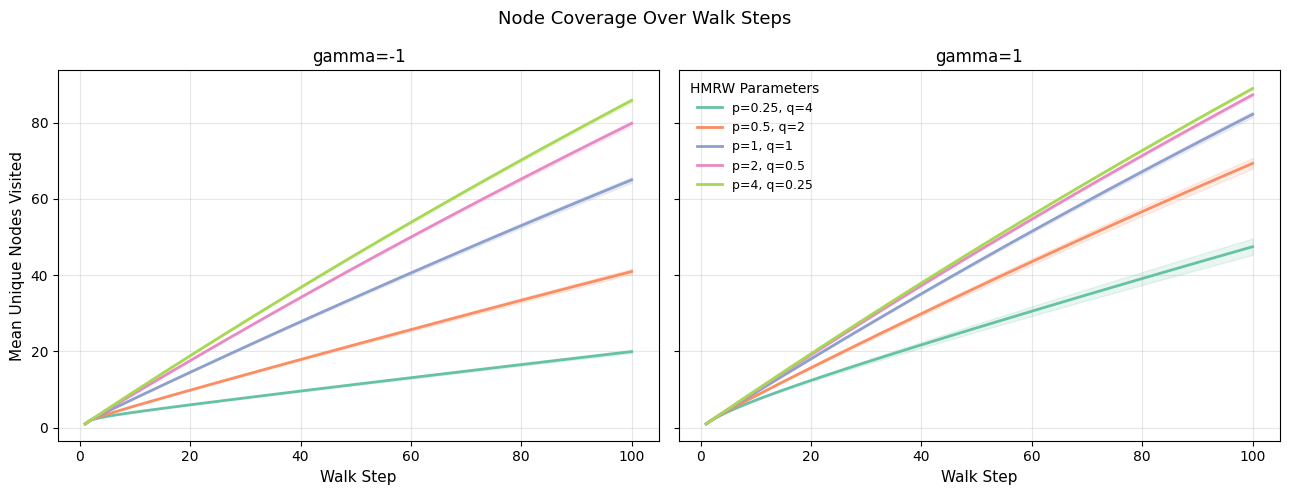

In [ ]:
# Two subplots: gamma = -1 and gamma = 1
fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, gamma_val in zip(axes, [-1.0, 1.0]):
    print(f"gamma = {gamma_val}")
    for i, (p_i, q_i) in enumerate(pq_grid):
        print(f"  p = {p_i}, q = {q_i}")
        curves = []
        for g, H in enumerate(Hs):
            walks_i, _, _ = sample_hmrw_walks(
                H,
                walk_length=walk_length,
                walks_per_node=walks_per_node,
                p=p_i,
                q=q_i,
                r=r_fixed,
                gamma=gamma_val,
                seed=100 + g,
            )
            curves.append(node_coverage_over_time(walks_i))

        C = np.vstack(curves)
        mean_c = C.mean(axis=0)
        std_c = C.std(axis=0)
        steps = np.arange(1, walk_length + 1)

        c = colors[i % len(colors)]
        ax.plot(steps, mean_c, color=c, lw=2, label=f"p={p_i}, q={q_i}")
        ax.fill_between(steps, mean_c - std_c, mean_c + std_c, color=c, alpha=0.15)

    ax.set_xlabel("Walk Step", fontsize=11)
    ax.set_title(f"gamma={gamma_val:.0f}", fontsize=12)
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Mean Unique Nodes Visited", fontsize=11)
axes[1].legend(frameon=False, title="HMRW Parameters", fontsize=9)
fig.suptitle("Node Coverage Over Walk Steps", fontsize=13)
fig.tight_layout()
fig.savefig(results_dir / "node_coverage_pq_gamma_subplots.png", dpi=300, bbox_inches="tight")
plt.show()

gamma = -1.0
  p = 0.25, q = 4
  p = 0.5, q = 2
  p = 1, q = 1
  p = 2, q = 0.5
  p = 4, q = 0.25
gamma = 1.0
  p = 0.25, q = 4
  p = 0.5, q = 2
  p = 1, q = 1
  p = 2, q = 0.5
  p = 4, q = 0.25


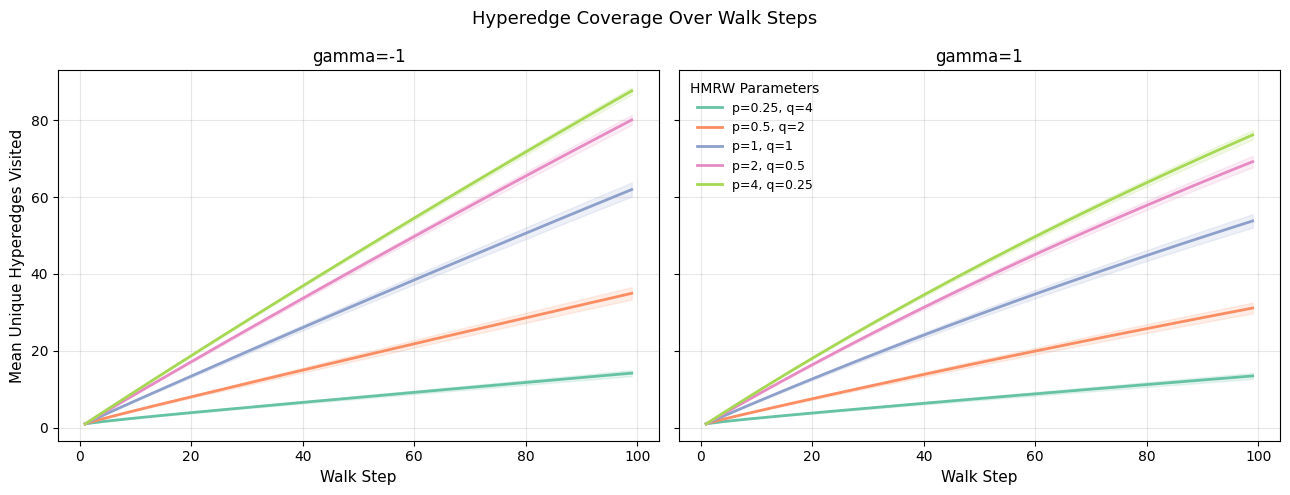

In [31]:
# Hyperedge coverage: same style as node coverage (gamma subplots)
colors = plt.get_cmap("Set2").colors

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)

for ax, gamma_val in zip(axes, [-1.0, 1.0]):
    print(f"gamma = {gamma_val}")
    for i, (p_i, q_i) in enumerate(pq_grid):
        print(f"  p = {p_i}, q = {q_i}")
        curves = []
        for g, H in enumerate(Hs):
            _, _, _, edge_walks_i = sample_hmrw_walks(
                H,
                walk_length=walk_length,
                walks_per_node=walks_per_node,
                p=p_i,
                q=q_i,
                r=r_fixed,
                gamma=gamma_val,
                seed=300 + g,
                return_edge_walks=True,
            )
            curves.append(hyperedge_coverage_over_time(edge_walks_i))

        C = np.vstack(curves)
        mean_c = C.mean(axis=0)
        std_c = C.std(axis=0)
        steps = np.arange(1, len(mean_c) + 1)

        c = colors[i % len(colors)]
        ax.plot(steps, mean_c, color=c, lw=2, label=f"p={p_i}, q={q_i}")
        ax.fill_between(steps, mean_c - std_c, mean_c + std_c, color=c, alpha=0.15)

    ax.set_xlabel("Walk Step", fontsize=11)
    ax.set_title(f"gamma={gamma_val:.0f}", fontsize=12)
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Mean Unique Hyperedges Visited", fontsize=11)
axes[1].legend(frameon=False, title="HMRW Parameters", fontsize=9)
fig.suptitle("Hyperedge Coverage Over Walk Steps", fontsize=13)
fig.tight_layout()
fig.savefig(results_dir / "hyperedge_coverage_pq_gamma_subplots.png", dpi=300, bbox_inches="tight")
plt.show()

In [12]:
# Diagnostic bar plot: one group per (p, q), bars = Stage-1 case frequencies
pq_grid = [
    (0.25, 4),
    (0.5, 2),
    (1, 1),
    (2, 0.5),
    (4, 0.25),
    (4, 4)
]

gamma_diag = -1.0
case_names = ["same hyperedge", "middle case", "other case"]

group_labels = [f"p={p_i}, q={q_i}" for (p_i, q_i) in pq_grid]
vals = []

for g_idx, (p_i, q_i) in enumerate(pq_grid):
    print(f"p = {p_i}, q = {q_i}")
    case_curves = []
    for h_idx, H in enumerate(Hs):
        _, case_freq, possible_freq = sample_hmrw_walks(
            H,
            walk_length=walk_length,
            walks_per_node=walks_per_node,
            p=p_i,
            q=q_i,
            r=r_fixed,
            gamma=gamma_diag,
            seed=200 + h_idx,
        )
        case_curves.append(case_freq)

    # Average over realizations and steps -> one value per case
    C = np.stack(case_curves, axis=0)      # (n_graphs, walk_length-1, 3)
    vals.append(C.mean(axis=(0, 1)))       # (3,)

vals = np.asarray(vals)  # (n_groups, 3)

x = np.arange(len(pq_grid))
bar_w = 0.26
case_colors = ["#66c2a5", "#fc8d62", "#8da0cb"]

fig, ax = plt.subplots(figsize=(9.5, 5.2))
for j, name in enumerate(case_names):
    ax.bar(x + (j - 1) * bar_w, vals[:, j], width=bar_w, color=case_colors[j], label=name)

ax.set_xticks(x)
ax.set_xticklabels(group_labels, rotation=20, ha="right")
ax.set_xlabel("Hyperparameter Set (p, q)", fontsize=11)
ax.set_ylabel("Mean Transition-Case Frequency", fontsize=11)
ax.set_title(f"Stage-1 Transition Cases by Hyperparameter Set (gamma={gamma_diag:.0f})", fontsize=12)
ax.grid(axis="y", alpha=0.3)
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(results_dir / "stage1_transition_cases_barplot.png", dpi=300, bbox_inches="tight")
plt.show()

Loaded cached table: results/walk_exploration/avgdeg_5/stage1_transition_cases_selected_vs_possible.csv


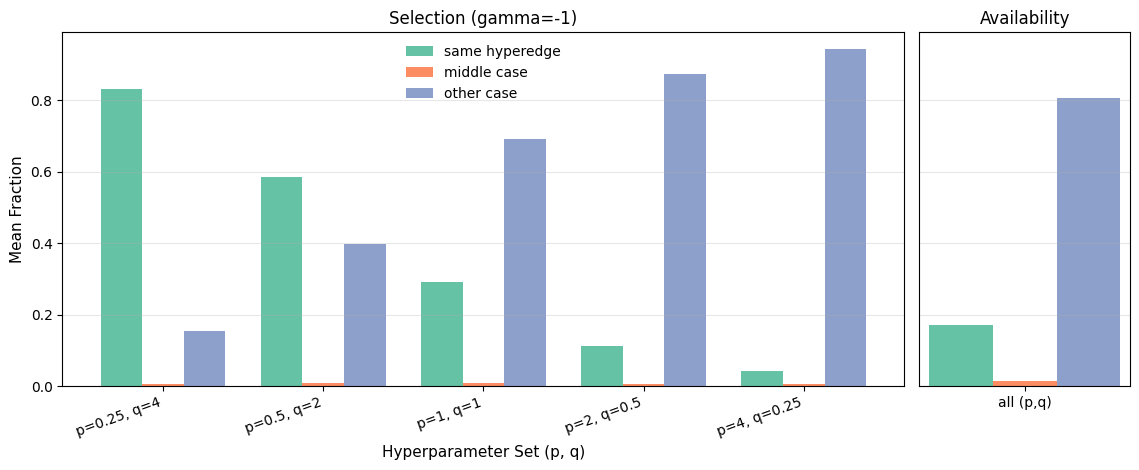

In [21]:
# Same plot with matched y-axis + load CSV cache if present
gamma_diag = -1.0
case_names = ["same hyperedge", "middle case", "other case"]
group_labels = [f"p={p_i}, q={q_i}" for (p_i, q_i) in pq_grid]

csv_path = results_dir / "stage1_transition_cases_selected_vs_possible.csv"

if csv_path.exists():
    df_cache = pd.read_csv(csv_path)
    selected_vals = df_cache[["selected_same", "selected_middle", "selected_other"]].to_numpy()
    possible_vals = df_cache[["possible_same", "possible_middle", "possible_other"]].to_numpy()
    print(f"Loaded cached table: {csv_path}")
else:
    selected_vals = []
    possible_vals = []

    for p_i, q_i in pq_grid:
        selected_curves = []
        possible_curves = []

        for h_idx, H in enumerate(Hs):
            _, case_freq, possible_freq = sample_hmrw_walks(
                H,
                walk_length=walk_length,
                walks_per_node=walks_per_node,
                p=p_i,
                q=q_i,
                r=r_fixed,
                gamma=gamma_diag,
                seed=200 + h_idx,
            )
            selected_curves.append(case_freq)
            possible_curves.append(possible_freq)

        selected_vals.append(np.stack(selected_curves, axis=0).mean(axis=(0, 1)))
        possible_vals.append(np.stack(possible_curves, axis=0).mean(axis=(0, 1)))

    selected_vals = np.asarray(selected_vals)
    possible_vals = np.asarray(possible_vals)

    rows = []
    for i, (p_i, q_i) in enumerate(pq_grid):
        rows.append({
            "p": p_i,
            "q": q_i,
            "selected_same": selected_vals[i, 0],
            "selected_middle": selected_vals[i, 1],
            "selected_other": selected_vals[i, 2],
            "possible_same": possible_vals[i, 0],
            "possible_middle": possible_vals[i, 1],
            "possible_other": possible_vals[i, 2],
        })

    pd.DataFrame(rows).to_csv(csv_path, index=False)
    print(f"Saved table: {csv_path}")

x = np.arange(len(pq_grid))
bar_w = 0.26
case_colors = ["#66c2a5", "#fc8d62", "#8da0cb"]

# Availability is effectively the same across hyperparameter sets; show one pooled group.
avail_one = possible_vals.mean(axis=0)

ymax = max(float(selected_vals.max()), float(avail_one.max()))

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.8), gridspec_kw={"width_ratios": [4, 1]})

# Left: selection by hyperparameter set
for j, name in enumerate(case_names):
    axes[0].bar(x + (j - 1) * bar_w, selected_vals[:, j], width=bar_w, color=case_colors[j], label=name)
axes[0].set_ylim(0.0, ymax * 1.05)
axes[0].set_ylabel("Mean Fraction", fontsize=11)
axes[0].set_xlabel("Hyperparameter Set (p, q)", fontsize=11)
axes[0].set_title(f"Selection (gamma={gamma_diag:.0f})", fontsize=12)
axes[0].grid(axis="y", alpha=0.3)
axes[0].set_xticks(x)
axes[0].set_xticklabels(group_labels, rotation=20, ha="right")
axes[0].legend(frameon=False)

# Right: one availability group (no separate y-axis)
x2 = np.array([0.0])
for j, _ in enumerate(case_names):
    axes[1].bar(x2 + (j - 1) * bar_w, [avail_one[j]], width=bar_w, color=case_colors[j])
axes[1].set_ylim(0.0, ymax * 1.05)
axes[1].set_title("Availability", fontsize=12)
axes[1].grid(axis="y", alpha=0.3)
axes[1].set_xticks([0.0])
axes[1].set_xticklabels(["all (p,q)"])
axes[1].tick_params(axis="y", left=False, labelleft=False)

fig.tight_layout()
fig.savefig(results_dir / "stage1_transition_cases_barplot_selected_vs_possible.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Community-aware node coverage over walk steps

# Use Hs_y created in the generation cell (single shared generator function).

pq_grid_mix = [(0.25, 4.0), (0.5, 2.0), (1.0, 1.0), (2.0, 0.5), (4.0, 0.25)]
walk_length_mix = 101   # steps 0..100
walks_per_node_mix = 10
r_fixed_mix = 1.0
colors = plt.get_cmap("Set2").colors

# Hs_y already prepared above

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), sharey=True)

for ax, gamma_val in zip(axes, [-1.0, 1.0]):
    for i, (p_i, q_i) in enumerate(pq_grid_mix):
        intra_curves = []
        inter_curves = []

        for g, (H_i, y_i) in enumerate(Hs_y):
            walks_i, _, _ = sample_hmrw_walks(
                H_i,
                walk_length=walk_length_mix,
                walks_per_node=walks_per_node_mix,
                p=p_i,
                q=q_i,
                r=r_fixed_mix,
                gamma=gamma_val,
                seed=500 + g,
            )
            intra_i, inter_i = community_aware_coverage_over_time(walks_i, y_i)
            intra_curves.append(intra_i)
            inter_curves.append(inter_i)

        C_intra = np.vstack(intra_curves)
        C_inter = np.vstack(inter_curves)

        mean_intra = C_intra.mean(axis=0)
        std_intra = C_intra.std(axis=0)
        mean_inter = C_inter.mean(axis=0)
        std_inter = C_inter.std(axis=0)

        steps = np.arange(len(mean_intra))  # 0..100
        c = colors[i % len(colors)]

        # Solid = intra-community, dashed = inter-community
        ax.plot(steps, mean_intra, color=c, lw=2, linestyle="-", label=f"p={p_i}, q={q_i} intra")
        ax.fill_between(steps, mean_intra - std_intra, mean_intra + std_intra, color=c, alpha=0.14)

        ax.plot(steps, mean_inter, color=c, lw=2, linestyle="--", label=f"p={p_i}, q={q_i} inter")
        ax.fill_between(steps, mean_inter - std_inter, mean_inter + std_inter, color=c, alpha=0.10)

    ax.set_title(f"gamma={gamma_val:.0f}", fontsize=12)
    ax.set_xlabel("Walk Step", fontsize=11)
    ax.grid(alpha=0.3)

axes[0].set_ylabel("Mean Unique Nodes Visited", fontsize=11)
axes[1].legend(frameon=False, fontsize=8, ncol=1)
fig.suptitle("Community-Aware Node Coverage Over Walk Steps", fontsize=13)
fig.tight_layout()
fig.savefig(results_dir / "community_aware_node_coverage_pq_gamma_subplots.png", dpi=300, bbox_inches="tight")
plt.show()

In [ ]:
# Cache tables for all coverage plots, then plot from CSV (no rerun needed next time)

pq_grid_cov = [(0.5, 0.5), (0.5, 2.0), (1.0, 1.0), (2.0, 0.5), (2.0, 2.0)]
pq_grid_mix = [(0.25, 4.0), (0.5, 2.0), (1.0, 1.0), (2.0, 0.5), (4.0, 0.25)]

gammas = [-1.0, 1.0]
walk_length_cov = 40
walk_length_mix = 101
walks_per_node_cov = 10
walks_per_node_mix = 10
r_fixed = 1.0
colors = plt.get_cmap("Set2").colors

node_csv = results_dir / "node_coverage_curves.csv"
hyper_csv = results_dir / "hyperedge_coverage_curves.csv"
comm_csv = results_dir / "community_coverage_curves.csv"

# ---------- NODE COVERAGE ----------
if node_csv.exists():
    node_df = pd.read_csv(node_csv)
else:
    rows = []
    for gamma_val in gammas:
        for p_i, q_i in pq_grid_cov:
            curves = []
            for g, H in enumerate(Hs):
                walks_i, _, _ = sample_hmrw_walks(
                    H,
                    walk_length=walk_length_cov,
                    walks_per_node=walks_per_node_cov,
                    p=p_i,
                    q=q_i,
                    r=r_fixed,
                    gamma=gamma_val,
                    seed=700 + g,
                )
                curves.append(node_coverage_over_time(walks_i))
            C = np.vstack(curves)
            mean_c = C.mean(axis=0)
            std_c = C.std(axis=0)
            for t in range(len(mean_c)):
                rows.append({"gamma": gamma_val, "p": p_i, "q": q_i, "step": t + 1, "mean": mean_c[t], "std": std_c[t]})
    node_df = pd.DataFrame(rows)
    node_df.to_csv(node_csv, index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, gamma_val in zip(axes, gammas):
    sub_g = node_df[node_df["gamma"] == gamma_val]
    for i, (p_i, q_i) in enumerate(pq_grid_cov):
        sub = sub_g[(sub_g["p"] == p_i) & (sub_g["q"] == q_i)].sort_values("step")
        c = colors[i % len(colors)]
        x = sub["step"].to_numpy()
        m = sub["mean"].to_numpy()
        s = sub["std"].to_numpy()
        ax.plot(x, m, color=c, lw=2, label=f"p={p_i}, q={q_i}")
        ax.fill_between(x, m - s, m + s, color=c, alpha=0.15)
    ax.set_xlabel("Walk Step", fontsize=11)
    ax.set_title(f"gamma={gamma_val:.0f}", fontsize=12)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Mean Unique Nodes Visited", fontsize=11)
axes[1].legend(frameon=False, title="HMRW Parameters", fontsize=9)
fig.suptitle("Node Coverage Over Walk Steps", fontsize=13)
fig.tight_layout()
fig.savefig(results_dir / "node_coverage_pq_gamma_subplots.png", dpi=300, bbox_inches="tight")
plt.show()

# ---------- HYPEREDGE COVERAGE ----------
if hyper_csv.exists():
    hyper_df = pd.read_csv(hyper_csv)
else:
    rows = []
    for gamma_val in gammas:
        for p_i, q_i in pq_grid_cov:
            curves = []
            for g, H in enumerate(Hs):
                _, _, _, edge_walks_i = sample_hmrw_walks(
                    H,
                    walk_length=walk_length_cov,
                    walks_per_node=walks_per_node_cov,
                    p=p_i,
                    q=q_i,
                    r=r_fixed,
                    gamma=gamma_val,
                    seed=800 + g,
                    return_edge_walks=True,
                )
                curves.append(hyperedge_coverage_over_time(edge_walks_i))
            C = np.vstack(curves)
            mean_c = C.mean(axis=0)
            std_c = C.std(axis=0)
            for t in range(len(mean_c)):
                rows.append({"gamma": gamma_val, "p": p_i, "q": q_i, "step": t + 1, "mean": mean_c[t], "std": std_c[t]})
    hyper_df = pd.DataFrame(rows)
    hyper_df.to_csv(hyper_csv, index=False)

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
for ax, gamma_val in zip(axes, gammas):
    sub_g = hyper_df[hyper_df["gamma"] == gamma_val]
    for i, (p_i, q_i) in enumerate(pq_grid_cov):
        sub = sub_g[(sub_g["p"] == p_i) & (sub_g["q"] == q_i)].sort_values("step")
        c = colors[i % len(colors)]
        x = sub["step"].to_numpy()
        m = sub["mean"].to_numpy()
        s = sub["std"].to_numpy()
        ax.plot(x, m, color=c, lw=2, label=f"p={p_i}, q={q_i}")
        ax.fill_between(x, m - s, m + s, color=c, alpha=0.15)
    ax.set_xlabel("Walk Step", fontsize=11)
    ax.set_title(f"gamma={gamma_val:.0f}", fontsize=12)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Mean Unique Hyperedges Visited", fontsize=11)
axes[1].legend(frameon=False, title="HMRW Parameters", fontsize=9)
fig.suptitle("Hyperedge Coverage Over Walk Steps", fontsize=13)
fig.tight_layout()
fig.savefig(results_dir / "hyperedge_coverage_pq_gamma_subplots.png", dpi=300, bbox_inches="tight")
plt.show()

# ---------- COMMUNITY-AWARE NODE COVERAGE ----------
if comm_csv.exists():
    comm_df = pd.read_csv(comm_csv)
else:
    rows = []
    for gamma_val in gammas:
        for p_i, q_i in pq_grid_mix:
            intra_curves = []
            inter_curves = []
            for g, (H_i, y_i) in enumerate(Hs_y):
                walks_i, _, _ = sample_hmrw_walks(
                    H_i,
                    walk_length=walk_length_mix,
                    walks_per_node=walks_per_node_mix,
                    p=p_i,
                    q=q_i,
                    r=r_fixed,
                    gamma=gamma_val,
                    seed=900 + g,
                )
                intra_i, inter_i = community_aware_coverage_over_time(walks_i, y_i)
                intra_curves.append(intra_i)
                inter_curves.append(inter_i)
            C_in = np.vstack(intra_curves)
            C_out = np.vstack(inter_curves)
            mi, si = C_in.mean(axis=0), C_in.std(axis=0)
            mo, so = C_out.mean(axis=0), C_out.std(axis=0)
            for t in range(len(mi)):
                rows.append({"gamma": gamma_val, "p": p_i, "q": q_i, "step": t, "type": "intra", "mean": mi[t], "std": si[t]})
                rows.append({"gamma": gamma_val, "p": p_i, "q": q_i, "step": t, "type": "inter", "mean": mo[t], "std": so[t]})
    comm_df = pd.DataFrame(rows)
    comm_df.to_csv(comm_csv, index=False)

fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2), sharey=True)
for ax, gamma_val in zip(axes, gammas):
    sub_g = comm_df[comm_df["gamma"] == gamma_val]
    for i, (p_i, q_i) in enumerate(pq_grid_mix):
        c = colors[i % len(colors)]
        sub_in = sub_g[(sub_g["p"] == p_i) & (sub_g["q"] == q_i) & (sub_g["type"] == "intra")].sort_values("step")
        sub_out = sub_g[(sub_g["p"] == p_i) & (sub_g["q"] == q_i) & (sub_g["type"] == "inter")].sort_values("step")
        x = sub_in["step"].to_numpy()
        mi, si = sub_in["mean"].to_numpy(), sub_in["std"].to_numpy()
        mo, so = sub_out["mean"].to_numpy(), sub_out["std"].to_numpy()
        ax.plot(x, mi, color=c, lw=2, linestyle="-", label=f"p={p_i}, q={q_i} intra")
        ax.fill_between(x, mi - si, mi + si, color=c, alpha=0.14)
        ax.plot(x, mo, color=c, lw=2, linestyle="--", label=f"p={p_i}, q={q_i} inter")
        ax.fill_between(x, mo - so, mo + so, color=c, alpha=0.10)
    ax.set_title(f"gamma={gamma_val:.0f}", fontsize=12)
    ax.set_xlabel("Walk Step", fontsize=11)
    ax.grid(alpha=0.3)
axes[0].set_ylabel("Mean Unique Nodes Visited", fontsize=11)
axes[1].legend(frameon=False, fontsize=8, ncol=1)
fig.suptitle("Community-Aware Node Coverage Over Walk Steps", fontsize=13)
fig.tight_layout()
fig.savefig(results_dir / "community_aware_node_coverage_pq_gamma_subplots.png", dpi=300, bbox_inches="tight")
plt.show()